**Nota de revisão:** a comparação atual usa somente a Árvore de Decisão oficial da Tarefa 5, Random Forest e XGBoost. Os resultados e interpretações anteriores foram retirados porque dependiam de outra divisão e do horizonte de 12 minutos. Preencher esta análise somente após executar novamente os notebooks e conferir os CSVs gerados.

**Consistência da árvore:** na comparação do detector, a árvore é carregada diretamente do artefato exportado pela Tarefa 5. No experimento de horizonte futuro e na avaliação de fluxos reservados, uma nova árvore é treinada com a *mesma configuração*, pois o alvo ou o conjunto de treinamento é diferente. Essas árvores auxiliares não são modelos oficiais adicionais. Execute a Tarefa 5 antes deste notebook.

In [1]:
%pip install scikit-learn==1.6.1 xgboost
import io, json, platform, time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (balanced_accuracy_score, confusion_matrix, f1_score,
                             precision_recall_fscore_support)
from sklearn.model_selection import ParameterGrid, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROCESSED = Path("/content/drive/MyDrive/ripe_atlas/processed")
    FIGURAS = PROCESSED / "tarefa6" / "figuras"
    MODELOS = PROCESSED / "tarefa6"
except ImportError:
    RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    PROCESSED = RAIZ / "data" / "processed"
    FIGURAS = RAIZ / "docs" / "img"
    MODELOS = RAIZ / "models"
SAIDA = PROCESSED / "tarefa6"
SAIDA.mkdir(exist_ok=True)
FIGURAS.mkdir(parents=True, exist_ok=True)

CLASSES = ["OK", "RISCO", "FALHA"]
FEATURES = ["z_robusto", "aumento_pct", "jitter_relativo", "perda_pct",
            "timeout_atual", "n5_timeout", "n5_aumento80", "n5_risco"]
RANDOM_STATE = 42
FOLGA_MEDICOES = 5
# O modelo de Árvore de Decisão vem da Tarefa 5; nunca escolher outra árvore na Tarefa 6.
PASTA_PROJETO = PROCESSED.parent
CAMINHOS_OFICIAL = [PASTA_PROJETO / "entrega_final" / "modelo.joblib",
                    PROCESSED / "artefatos_notebooks" / "arvore_final.joblib"]
CAMINHO_OFICIAL = next((p for p in CAMINHOS_OFICIAL if p.exists()), None)
if CAMINHO_OFICIAL is None:
    raise FileNotFoundError("Execute a Tarefa 5 e disponibilize entrega_final/modelo.joblib ou artefatos_notebooks/arvore_final.joblib")
ARTEFATO_OFICIAL = joblib.load(CAMINHO_OFICIAL)
MODELO_OFICIAL = ARTEFATO_OFICIAL["modelo"] if isinstance(ARTEFATO_OFICIAL, dict) else ARTEFATO_OFICIAL
if isinstance(ARTEFATO_OFICIAL, dict) and list(ARTEFATO_OFICIAL["features"]) != FEATURES:
    raise ValueError("Features da Árvore de Decisão diferentes das features da Tarefa 6")
ARVORE_OFICIAL = MODELO_OFICIAL.named_steps["arvore"]
PARAMS_OFICIAL = {"criterion": ARVORE_OFICIAL.criterion,
                  "max_depth": ARVORE_OFICIAL.max_depth,
                  "min_samples_leaf": ARVORE_OFICIAL.min_samples_leaf,
                  "balanceado": False}
print("Árvore de Decisão carregada:", CAMINHO_OFICIAL, PARAMS_OFICIAL)
CORES = {"OK": "#23866d", "RISCO": "#bd8420", "FALHA": "#c34e55"}
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

print("Python", platform.python_version(), "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__,
      "| pandas", pd.__version__, "| numpy", np.__version__)

det = pd.read_csv(PROCESSED / "dataset_B_com_recorte_temporal.csv", low_memory=False)
det["timestamp_utc"] = pd.to_datetime(det["timestamp_utc"], utc=True)
pred_futuro = pd.read_csv(PROCESSED / "dataset_predicao.csv", low_memory=False)
pred_futuro["timestamp_utc"] = pd.to_datetime(pred_futuro["timestamp_utc"], utc=True)
print(det["bloco_temporal"].value_counts().to_dict())
print(det["classe"].value_counts().reindex(CLASSES).to_dict())
assert not det.empty and set(FEATURES) <= set(det.columns)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Árvore de Decisão carregada: /content/drive/MyDrive/ripe_atlas/entrega_final/modelo.joblib {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 10, 'balanceado': False}
Python 3.13.18 | scikit-learn 1.6.1 | xgboost 3.4.1 | pandas 2.2.3 | numpy 2.4.6
{'treino': 25545, 'validacao': 5102, 'teste': 3417}
{'OK': 26274, 'RISCO': 3848, 'FALHA': 3942}


## 1. Funções usadas em todos os modelos

Tudo fica em `Pipeline`, com a imputação ajustada só no treino. O XGBoost exige as classes como números, então o alvo é codificado da mesma forma para os três modelos. A ordem fica FALHA = 0, OK = 1, RISCO = 2.

In [2]:
cod = LabelEncoder().fit(CLASSES)
I_FALHA = int(cod.transform(["FALHA"])[0])
y_cod = lambda serie: cod.transform(serie)


def novo_modelo(familia, params):
    p = {k: v for k, v in params.items() if k != "balanceado"}
    if familia == "arvore":
        m = DecisionTreeClassifier(random_state=RANDOM_STATE, **p)
    elif familia == "floresta":
        m = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **p)
    else:
        m = XGBClassifier(random_state=RANDOM_STATE, n_jobs=-1, eval_metric="mlogloss", **p)
    return Pipeline([("imputer", SimpleImputer(strategy="median")), ("modelo", m)])


def treinar(familia, params, X, y):
    modelo = novo_modelo(familia, params)
    pesos = compute_sample_weight("balanced", y) if params.get("balanceado") else None
    return modelo.fit(X, y, modelo__sample_weight=pesos)


def prever(modelo, X, limiar=None):
    # Reordena as probabilidades segundo o codificador comum, inclusive quando
    # a Árvore de Decisão da Tarefa 5 foi treinada com rótulos em texto.
    proba_original = modelo.predict_proba(X)
    classes_modelo = modelo.classes_ if hasattr(modelo, "classes_") else modelo.steps[-1][1].classes_
    classes_modelo = np.asarray(classes_modelo)
    if classes_modelo.dtype.kind in "OUS":
        indices = cod.transform(classes_modelo.astype(str))
    else:
        indices = classes_modelo.astype(int)
    proba = np.zeros((len(X), len(CLASSES)), dtype=float)
    proba[:, indices] = proba_original
    if limiar is None:
        return proba.argmax(axis=1)
    sem_falha = proba.copy()
    sem_falha[:, I_FALHA] = -1
    return np.where(proba[:, I_FALHA] >= limiar, I_FALHA, sem_falha.argmax(axis=1))

def nomes(y):
    return cod.inverse_transform(y)


def metricas(y, pred):
    # y e pred com os nomes das classes.
    p, r, f, s = precision_recall_fscore_support(y, pred, labels=CLASSES, zero_division=0)
    cm = confusion_matrix(y, pred, labels=CLASSES)
    return {"F1 macro": f1_score(y, pred, labels=CLASSES, average="macro", zero_division=0),
            "Recall FALHA": r[2], "Recall RISCO": r[1], "Precisão FALHA": p[2], "Precisão RISCO": p[1],
            "Balanced acc.": balanced_accuracy_score(y, pred), "Acurácia": float(np.mean(np.asarray(y) == np.asarray(pred))),
            "FALHA→RISCO": int(cm[2, 1]), "RISCO→FALHA": int(cm[1, 2]), "FALHA→OK": int(cm[2, 0]),
            "Erros": int(len(y) - np.trace(cm)), "N": int(len(y))}


def tirar_folga(tabela):
    # Tira as primeiras medições de cada fluxo no bloco (ver Protocolo, item 3).
    ordem = tabela.sort_values("timestamp_utc").groupby("fluxo_id").cumcount()
    return tabela.loc[ordem[ordem >= FOLGA_MEDICOES].index]


def blocos(tabela):
    return (tabela[tabela.bloco_temporal.eq("treino")].sort_values("timestamp_utc"),
            tabela[tabela.bloco_temporal.eq("validacao")],
            tabela[tabela.bloco_temporal.eq("teste")])


treino, validacao, teste = blocos(det)
val_f, teste_f = tirar_folga(validacao), tirar_folga(teste)
print("Treino", len(treino), "| validação sem folga", len(val_f), "de", len(validacao),
      "| teste sem folga", len(teste_f), "de", len(teste))


Treino 25545 | validação sem folga 5022 de 5102 | teste sem folga 3337 de 3417


## 2. Conferência: a Árvore de Decisão continua a mesma?

Antes de comparar qualquer coisa, a árvore com os parâmetros da Tarefa 4 precisa repetir o teste da Tarefa 5, sem folga: 4 erros, F1 macro 0,9991 e recall de FALHA 0,9962.

In [3]:
oficial = MODELO_OFICIAL
conf = metricas(teste["classe"], nomes(prever(oficial, teste[FEATURES])))
print({k: round(conf[k], 4) for k in ["Erros", "F1 macro", "Recall FALHA", "Acurácia"]})
print(pd.DataFrame(confusion_matrix(teste["classe"], nomes(prever(oficial, teste[FEATURES])), labels=CLASSES),
                   index=[f"Real {x}" for x in CLASSES], columns=[f"Previsto {x}" for x in CLASSES]))
assert np.isfinite(conf["F1 macro"]) and 0 <= conf["F1 macro"] <= 1
print("Avaliação concluída: compare com a Tarefa 5 executada no MESMO dataset.")


{'Erros': 3, 'F1 macro': 0.9978, 'Recall FALHA': np.float64(0.9968), 'Acurácia': 0.9991}
            Previsto OK  Previsto RISCO  Previsto FALHA
Real OK            2788               0               0
Real RISCO            2             315               0
Real FALHA            0               1             311
Avaliação concluída: compare com a Tarefa 5 executada no MESMO dataset.


## 3. Busca de hiperparâmetros

A busca nunca toca o teste. Cada família testa 24 configurações, com e sem peso por classe. O `fit` e a nota saem só do bloco de treino, em ordem de tempo.

In [4]:
GRADES = {
    "floresta": {"n_estimators": [100, 200], "max_depth": [6, 12, None], "max_features": ["sqrt", None],
                 "min_samples_leaf": [1, 10], "balanceado": [False, True]},
    "xgboost": {"n_estimators": [100, 200], "max_depth": [3, 6], "learning_rate": [0.05, 0.1, 0.3],
                "reg_lambda": [1, 5], "balanceado": [False, True]},
}
print({k: len(ParameterGrid(v)) for k, v in GRADES.items()})


def buscar_cv(alvo, tr, rotulo):
    # Validação cruzada temporal dentro do treino. Devolve os melhores parâmetros de cada família.
    cv = TimeSeriesSplit(n_splits=3, gap=80)
    X, y = tr[FEATURES], y_cod(tr[alvo])
    melhores = {}
    for familia, grade in GRADES.items():
        inicio = time.perf_counter()
        linhas = []
        for params in ParameterGrid(grade):
            f1s, recs = [], []
            for i_tr, i_va in cv.split(X):
                m = treinar(familia, params, X.iloc[i_tr], y[i_tr])
                real, previsto = nomes(y[i_va]), nomes(prever(m, X.iloc[i_va]))
                r = metricas(real, previsto)
                f1s.append(r["F1 macro"]); recs.append(r["Recall FALHA"])
            linhas.append({"params": json.dumps(params), "F1 macro CV": np.mean(f1s), "Recall FALHA CV": np.mean(recs)})
        tabela = pd.DataFrame(linhas).sort_values(["F1 macro CV", "Recall FALHA CV"], ascending=False)
        tabela.to_csv(SAIDA / f"busca_{rotulo}_{familia}.csv", index=False)
        melhores[familia] = json.loads(tabela.iloc[0]["params"])
        print(f"{familia:<9} {time.perf_counter() - inicio:6.0f} s | F1 CV {tabela.iloc[0]['F1 macro CV']:.4f} | {melhores[familia]}")
    return melhores


melhores_det = buscar_cv("classe", treino, "detector")


{'floresta': 48, 'xgboost': 48}
floresta     436 s | F1 CV 0.9990 | {'balanceado': False, 'max_depth': 12, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 100}
xgboost      133 s | F1 CV 0.9990 | {'balanceado': True, 'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200, 'reg_lambda': 1}


## 4. Modelos finais, limiar e escolha na validação

Os modelos finais são treinados só no bloco de treino. O XGBoost usa parada antecipada (`early_stopping_rounds=30`) com o bloco de validação, que fica depois do treino no tempo.

O limiar é testado de 0,10 a 0,90 sobre a probabilidade de FALHA. O padrão é a classe mais provável, e um limiar só substitui o padrão se melhorar o F1 macro ou, em empate, o recall de FALHA da validação.

In [5]:
def final_xgboost(params, tr, va, alvo):
    p = {k: v for k, v in params.items() if k not in ("balanceado", "n_estimators")}
    imputer = SimpleImputer(strategy="median").fit(tr[FEATURES])
    m = XGBClassifier(random_state=RANDOM_STATE, n_jobs=-1, eval_metric="mlogloss", n_estimators=1000,
                      early_stopping_rounds=30, **p)
    y_tr = y_cod(tr[alvo])
    pesos = compute_sample_weight("balanced", y_tr) if params.get("balanceado") else None
    m.fit(imputer.transform(tr[FEATURES]), y_tr, sample_weight=pesos,
          eval_set=[(imputer.transform(va[FEATURES]), y_cod(va[alvo]))], verbose=False)
    return Pipeline([("imputer", imputer), ("modelo", m)])


def escolher_limiar(modelo, va, alvo):
    real = va[alvo].values
    base = metricas(real, nomes(prever(modelo, va[FEATURES])))
    melhor_lim, melhor = None, (base["F1 macro"], base["Recall FALHA"])
    for lim in np.arange(0.10, 0.91, 0.05).round(2):
        r = metricas(real, nomes(prever(modelo, va[FEATURES], lim)))
        if (r["F1 macro"], r["Recall FALHA"]) > melhor:
            melhor_lim, melhor = float(lim), (r["F1 macro"], r["Recall FALHA"])
    return melhor_lim


def montar_finais(melhores, tr, va_folga, alvo, com_oficial=True):
    finais = {}
    if com_oficial:
        finais["Árvore de Decisão"] = ("arvore", PARAMS_OFICIAL)
    finais["Random Forest"] = ("floresta", melhores["floresta"])
    finais["XGBoost"] = ("xgboost", melhores["xgboost"])
    saida = {}
    for nome, (familia, params) in finais.items():
        inicio = time.perf_counter()
        if familia == "arvore" and alvo == "classe":
            # Usa o MESMO objeto treinado e exportado na Tarefa 5.
            m = MODELO_OFICIAL
        elif familia == "xgboost":
            m = final_xgboost(params, tr, va_folga, alvo)
        else:
            # Para status_futuro, a árvore usa a mesma configuração, mas
            # precisa ser treinada para esse alvo diferente.
            m = treinar(familia, params, tr[FEATURES], y_cod(tr[alvo]))
        duracao = time.perf_counter() - inicio
        saida[nome] = {"familia": familia, "params": params, "modelo": m, "treino_s": duracao,
                       "limiar": escolher_limiar(m, va_folga, alvo)}
    return saida


finais = montar_finais(melhores_det, treino, val_f, "classe")

linhas = []
for nome, info in finais.items():
    r = metricas(val_f["classe"].values, nomes(prever(info["modelo"], val_f[FEATURES], info["limiar"])))
    linhas.append({"Modelo": nome, "Limiar": info["limiar"], **r})
tab_val = pd.DataFrame(linhas).set_index("Modelo")
tab_val.round(4).to_csv(SAIDA / "comparacao_validacao_detector.csv")
display(tab_val[["Limiar", "F1 macro", "Recall FALHA", "Recall RISCO", "Balanced acc.", "Erros", "N"]].round(4))

# Regra de decisão fixada no Protocolo, antes de abrir o teste.
MARGEM = 0.002
perto = tab_val[(tab_val["F1 macro"] >= tab_val["F1 macro"].max() - MARGEM)
                & (tab_val["Recall FALHA"] >= tab_val["Recall FALHA"].max() - MARGEM)]
ordem_simplicidade = ["Árvore de Decisão", "Random Forest", "XGBoost"]
ESCOLHIDO = next((n for n in ordem_simplicidade if n in perto.index), tab_val["F1 macro"].idxmax())
print("Candidatos dentro da margem:", list(perto.index))
print("Modelo escolhido na validação:", ESCOLHIDO)


,Limiar,F1 macro,Recall FALHA,Recall RISCO,Balanced acc.,Erros,N
Modelo,,,,,,,
Árvore de Decisão,NaN,0.9985,0.9965,0.9958,0.9974,4,5022
Random Forest,NaN,0.9985,0.9965,0.9958,0.9974,4,5022
XGBoost,0.1,0.9993,0.9965,1.0000,0.9988,2,5022


Candidatos dentro da margem: ['Árvore de Decisão', 'Random Forest', 'XGBoost']
Modelo escolhido na validação: Árvore de Decisão


## 5. Teste temporal

Só agora o teste entra, com a folga, para todos os modelos. Nada é reajustado depois daqui. A classe majoritária é o piso: prevê sempre OK.

In [6]:
def tamanho_kb(modelo):
    buffer = io.BytesIO()
    joblib.dump(modelo, buffer)
    return buffer.tell() / 1024


def latencia_linha_ms(modelo, X):
    amostra = X.iloc[:200]
    inicio = time.perf_counter()
    for i in range(len(amostra)):
        modelo.predict(amostra.iloc[[i]])
    return (time.perf_counter() - inicio) / len(amostra) * 1000


maj = treino["classe"].mode()[0]
linhas = [{"Modelo": "Classe majoritária", "Limiar": None, **metricas(teste_f["classe"].values, np.full(len(teste_f), maj)),
           "Treino (s)": 0.0, "Predição (ms/1.000)": 0.0, "Latência 1 linha (ms)": 0.0, "Tamanho (KB)": 0.0}]
por_classe, previsoes = [], {}
for nome, info in finais.items():
    inicio = time.perf_counter()
    previsto = nomes(prever(info["modelo"], teste_f[FEATURES], info["limiar"]))
    dur = time.perf_counter() - inicio
    previsoes[nome] = previsto
    linhas.append({"Modelo": nome, "Limiar": info["limiar"], **metricas(teste_f["classe"].values, previsto),
                   "Treino (s)": info["treino_s"], "Predição (ms/1.000)": dur / len(teste_f) * 1e6,
                   "Latência 1 linha (ms)": latencia_linha_ms(info["modelo"], teste_f[FEATURES]),
                   "Tamanho (KB)": tamanho_kb(info["modelo"])})
    p, r, f, s = precision_recall_fscore_support(teste_f["classe"], previsto, labels=CLASSES, zero_division=0)
    for i, cl in enumerate(CLASSES):
        por_classe.append({"Modelo": nome, "Classe": cl, "Precisão": p[i], "Recall": r[i], "F1": f[i], "Suporte": int(s[i])})

tab_teste = pd.DataFrame(linhas).set_index("Modelo")
tab_teste.round(4).to_csv(SAIDA / "comparacao_detector.csv")
pd.DataFrame(por_classe).round(4).to_csv(SAIDA / "metricas_por_classe.csv", index=False)
display(tab_teste[["Limiar", "F1 macro", "Recall FALHA", "Recall RISCO", "Balanced acc.", "Acurácia", "Erros",
                   "FALHA→OK", "FALHA→RISCO", "RISCO→FALHA", "N"]].round(4))
display(tab_teste[["Treino (s)", "Predição (ms/1.000)", "Latência 1 linha (ms)", "Tamanho (KB)"]].round(3))
display(pd.DataFrame(por_classe).pivot(index="Modelo", columns="Classe", values=["Precisão", "Recall", "F1"]).round(4))
print("XGBoost parou com", finais["XGBoost"]["modelo"].named_steps["modelo"].best_iteration + 1, "árvores.")


,Limiar,F1 macro,Recall FALHA,Recall RISCO,Balanced acc.,Acurácia,Erros,FALHA→OK,FALHA→RISCO,RISCO→FALHA,N
Modelo,,,,,,,,,,,
Classe majoritária,NaN,0.2994,0.0000,0.0000,0.3333,0.8151,617,306,0,0,3337
Árvore de Decisão,NaN,0.9977,0.9967,0.9936,0.9968,0.9991,3,0,1,0,3337
Random Forest,NaN,0.9989,0.9967,1.0000,0.9989,0.9997,1,0,1,0,3337
XGBoost,0.1,0.9988,1.0000,0.9968,0.9988,0.9994,2,0,0,0,3337


,Treino (s),Predição (ms/1.000),Latência 1 linha (ms),Tamanho (KB)
Modelo,,,,
Classe majoritária,0.000,0.000,0.000,0.000
Árvore de Decisão,0.000,1.515,2.279,5.479
Random Forest,2.469,17.993,30.653,1873.080
XGBoost,1.612,8.748,2.717,669.230


Precisão                  Recall                      F1  \
Classe               FALHA      OK   RISCO   FALHA      OK   RISCO   FALHA   
Modelo                                                                       
Random Forest          1.0  1.0000  0.9968  0.9967  1.0000  1.0000  0.9984   
XGBoost                1.0  0.9996  0.9968  1.0000  0.9996  0.9968  1.0000   
Árvore de Decisão      1.0  0.9993  0.9968  0.9967  1.0000  0.9936  0.9984   

                                   
Classe                 OK   RISCO  
Modelo                             
Random Forest      1.0000  0.9984  
XGBoost            0.9996  0.9968  
Árvore de Decisão  0.9996  0.9952

XGBoost parou com 189 árvores.


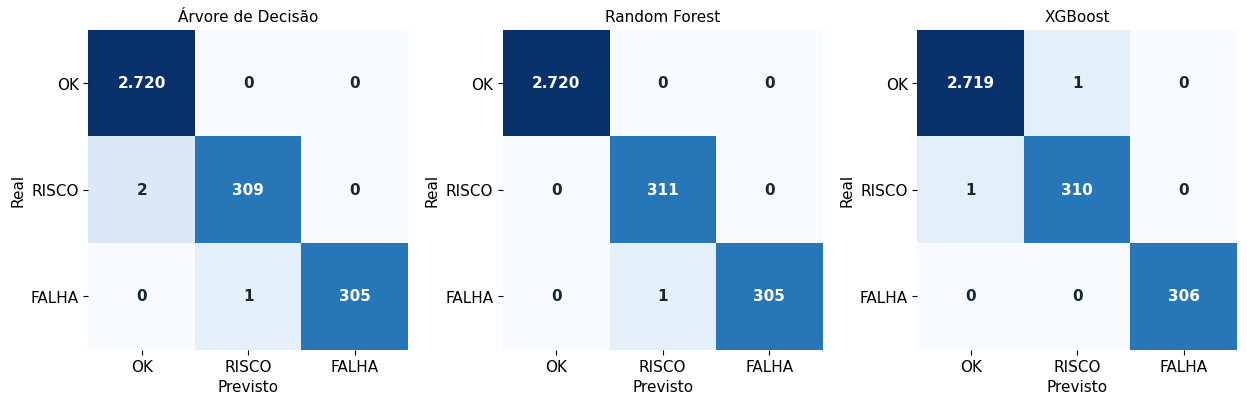

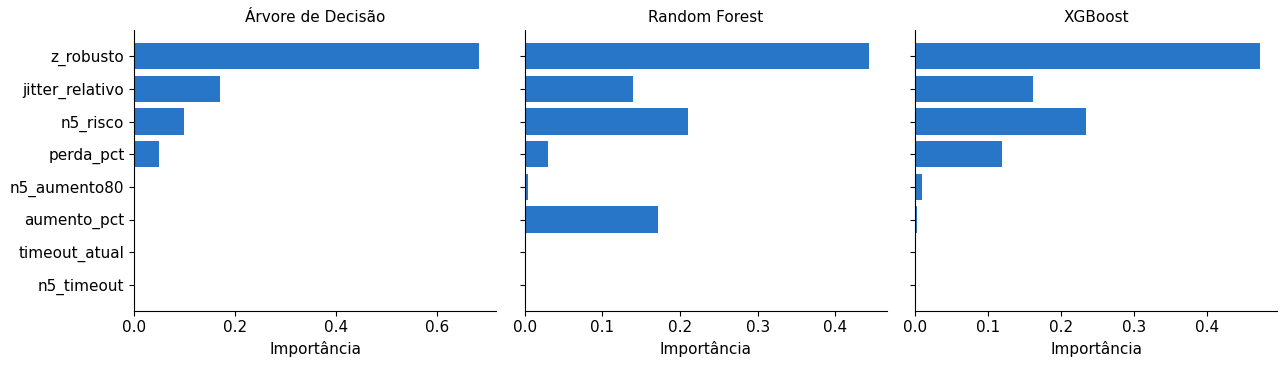

,Árvore de Decisão,Random Forest,XGBoost
z_robusto,0.6827,0.4435,0.4724
aumento_pct,0.0002,0.1712,0.0029
jitter_relativo,0.1693,0.1399,0.1610
perda_pct,0.0492,0.0301,0.1197
timeout_atual,0.0000,0.0012,0.0000
n5_timeout,0.0000,0.0004,0.0000
n5_aumento80,0.0009,0.0037,0.0093
n5_risco,0.0977,0.2100,0.2346


In [8]:

# Matrizes de confusão em contagem, uma para cada modelo.
fig, eixos = plt.subplots(1, len(finais), figsize=(4.2 * len(finais), 4))

for eixo, (nome, previsto) in zip(eixos, previsoes.items()):
    cm = confusion_matrix(teste_f["classe"], previsto, labels=CLASSES)
    eixo.imshow(np.log1p(cm), cmap="Blues")
    eixo.set_title(nome, fontsize=11)
    eixo.set_xticks(range(3), CLASSES)
    eixo.set_yticks(range(3), CLASSES)
    eixo.set_xlabel("Previsto")
    eixo.set_ylabel("Real")
    eixo.spines[:].set_visible(False)

    for i in range(3):
        for j in range(3):
            eixo.text(
                j, i,
                f"{cm[i, j]:,}".replace(",", "."),
                ha="center", va="center",
                color="white" if cm[i, j] > 300 else "#182638",
                fontweight="bold"
            )

fig.tight_layout()
fig.savefig(FIGURAS / "matrizes_confusao.png", dpi=150, bbox_inches="tight")
plt.show()


# Função para encontrar o estimador de cada modelo.
def obter_estimador(pipeline):
    if hasattr(pipeline, "feature_importances_"):
        return pipeline

    if hasattr(pipeline, "named_steps"):
        for etapa in reversed(list(pipeline.named_steps.values())):
            if hasattr(etapa, "feature_importances_"):
                return etapa

    raise ValueError(
        "Não foi encontrado um estimador com feature_importances_."
    )


# Importância dos atributos.
nomes_modelos = ["Árvore de Decisão", "Random Forest", "XGBoost"]

importancias = {}

for nome in nomes_modelos:
    pipeline = finais[nome]["modelo"]
    estimador = obter_estimador(pipeline)

    importancias[nome] = pd.Series(
        estimador.feature_importances_,
        index=FEATURES
    )

# Mesma ordem de atributos nos três gráficos.
ordem = importancias["Árvore de Decisão"].sort_values().index

fig, eixos = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)

for eixo, nome in zip(eixos, nomes_modelos):
    imp = importancias[nome]

    eixo.barh(ordem, imp[ordem], color="#2876c7")
    eixo.set_title(nome, fontsize=11)
    eixo.set_xlabel("Importância")

fig.tight_layout()
fig.savefig(FIGURAS / "importancia_atributos.png", dpi=150, bbox_inches="tight")
plt.show()

# Exportar importâncias reais para CSV.
tabela_importancias = pd.DataFrame(importancias, index=FEATURES)

tabela_importancias.round(4).to_csv(
    SAIDA / "importancia_atributos.csv"
)

display(tabela_importancias.round(4))


### A figura da árvore

As figuras gravadas nas Tarefas 3 e 4 passavam `class_names=CLASSES`, na ordem OK, RISCO, FALHA. O scikit-learn guarda as classes em ordem alfabética (FALHA, OK, RISCO), então o desenho saía com os nomes trocados, embora as regras em texto estivessem certas. As células daquelas tarefas foram corrigidas. Aqui os nomes vêm do próprio modelo.

Para a figura, a árvore é treinada com os nomes das classes, de modo que `classes_` sai igual ao modelo entregue.

Ordem das classes no modelo: ['FALHA', 'OK', 'RISCO']


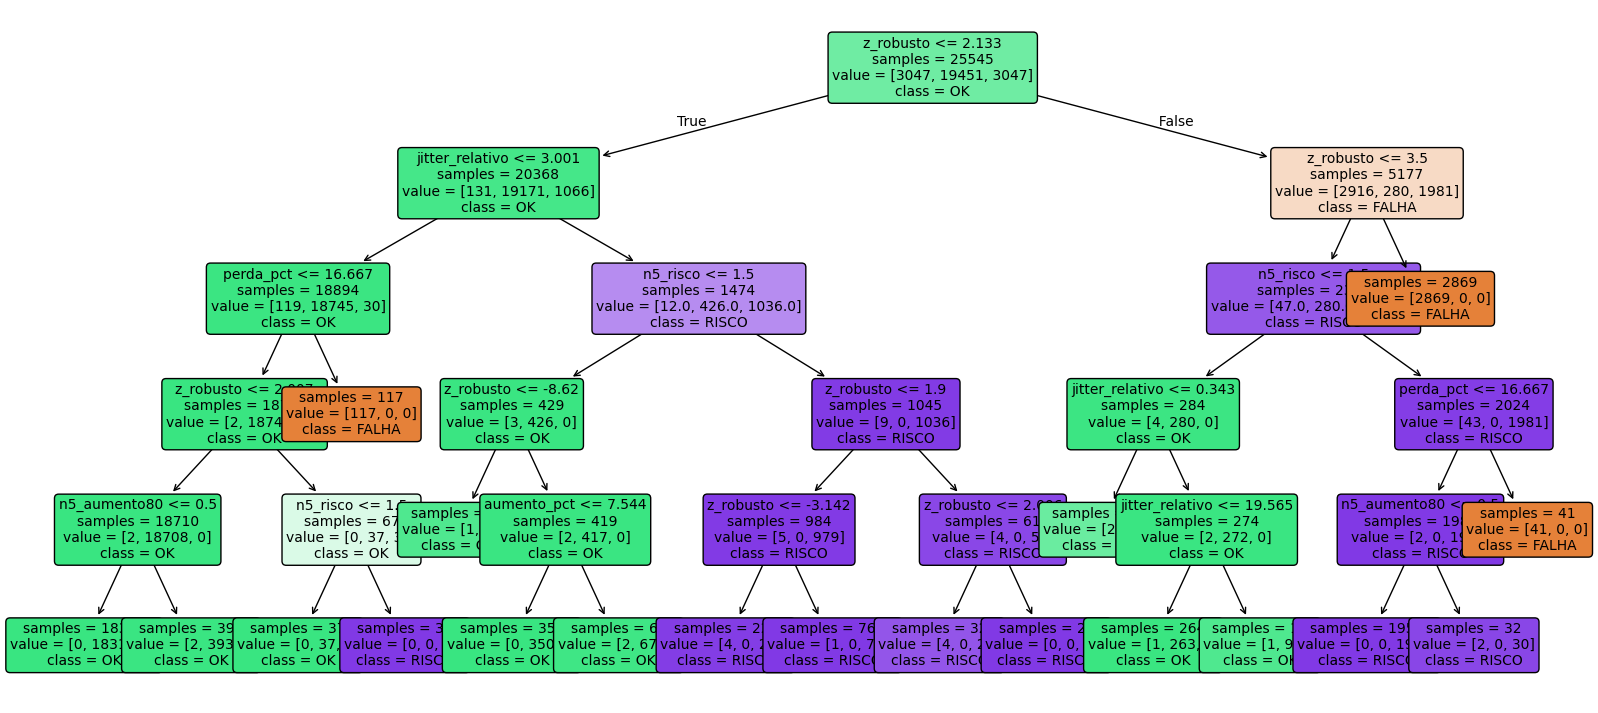

,profundidade,F1 treino,F1 validação,folhas
0,1,0.5552,0.5527,2
1,2,0.9439,0.9327,4
2,3,0.9932,0.9975,7
3,4,0.9994,0.9982,12
4,5,0.9996,0.9982,14
5,6,1.0000,0.9985,15
6,8,1.0000,0.9985,15
7,10,1.0000,0.9985,15
8,15,1.0000,0.9985,15
9,sem limite,1.0000,0.9985,15


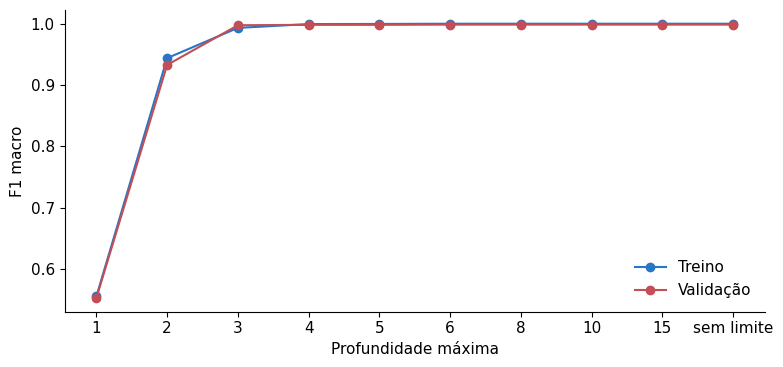

Acurácia out-of-bag da floresta: 0.9998


In [9]:
arvore_nomes = MODELO_OFICIAL.named_steps["arvore"]
print("Ordem das classes no modelo:", list(arvore_nomes.classes_))
plt.figure(figsize=(20, 9))
plot_tree(arvore_nomes, feature_names=FEATURES, class_names=list(arvore_nomes.classes_), filled=True, rounded=True,
          impurity=False, fontsize=10)
plt.savefig(FIGURAS / "arvore_oficial.png", dpi=130, bbox_inches="tight")
plt.show()

# Profundidade x overfitting: treino e validação, sem mexer no teste.
curva = []
for prof in [1, 2, 3, 4, 5, 6, 8, 10, 15, None]:
    m = treinar("arvore", {"criterion": "gini", "max_depth": prof, "min_samples_leaf": 1}, treino[FEATURES], y_cod(treino["classe"]))
    curva.append({"profundidade": "sem limite" if prof is None else prof,
                  "F1 treino": metricas(treino["classe"].values, nomes(prever(m, treino[FEATURES])))["F1 macro"],
                  "F1 validação": metricas(val_f["classe"].values, nomes(prever(m, val_f[FEATURES])))["F1 macro"],
                  "folhas": m.named_steps["modelo"].get_n_leaves()})
curva = pd.DataFrame(curva)
curva.round(4).to_csv(SAIDA / "curva_profundidade.csv", index=False)
display(curva.round(4))
plt.figure(figsize=(8, 3.8))
x = range(len(curva))
plt.plot(x, curva["F1 treino"], marker="o", color="#2876c7", label="Treino")
plt.plot(x, curva["F1 validação"], marker="o", color="#c34e55", label="Validação")
plt.xticks(x, curva["profundidade"]); plt.xlabel("Profundidade máxima"); plt.ylabel("F1 macro"); plt.legend(frameon=False)
plt.tight_layout(); plt.savefig(FIGURAS / "curva_profundidade.png", dpi=150); plt.show()

# Erro out-of-bag da floresta, para fechar os conceitos do artigo.
oob_params = {k: v for k, v in melhores_det["floresta"].items() if k != "balanceado"}
imputado = SimpleImputer(strategy="median").fit_transform(treino[FEATURES])
oob = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, oob_score=True, **oob_params).fit(imputado, y_cod(treino["classe"]))
print("Acurácia out-of-bag da floresta:", round(oob.oob_score_, 4))


## 6. O alvo futuro: 20 minutos à frente

O preditor só tem utilidade se superar a persistência, a regra que repete o estado atual. As colunas de entrada continuam as oito de sempre, em `t`. O alvo é `status_futuro`, a classe do mesmo fluxo perto de `t + 20 min` (±60 s), ou seja, cerca de 5 medições depois (aproximadamente; depende da cadência). Pares cujo alvo cairia em outro bloco já foram descartados na Tarefa 2.

In [10]:
tr_p, va_p, te_p = blocos(pred_futuro)
va_pf, te_pf = tirar_folga(va_p), tirar_folga(te_p)
print("Treino", len(tr_p), "| validação", len(va_pf), "| teste", len(te_pf))

melhores_pred = buscar_cv("status_futuro", tr_p, "preditor")
finais_pred = montar_finais(melhores_pred, tr_p, va_pf, "status_futuro", com_oficial=True)

maj_p = tr_p["status_futuro"].mode()[0]
real = te_pf["status_futuro"].values
linhas = [{"Modelo": "Classe majoritária", "Limiar": None, **metricas(real, np.full(len(real), maj_p))},
          {"Modelo": "Persistência", "Limiar": None, **metricas(real, te_pf["previsao_persistencia"].values)}]
for nome, info in finais_pred.items():
    linhas.append({"Modelo": nome, "Limiar": info["limiar"], **metricas(real, nomes(prever(info["modelo"], te_pf[FEATURES], info["limiar"])))})
tab_pred = pd.DataFrame(linhas).set_index("Modelo")
tab_pred.round(4).to_csv(SAIDA / "comparacao_preditor.csv")
display(tab_pred[["Limiar", "F1 macro", "Recall FALHA", "Recall RISCO", "Balanced acc.", "Acurácia", "Erros", "N"]].round(4))

pers = tab_pred.loc["Persistência"]
modelos_p = tab_pred.drop(["Classe majoritária", "Persistência"])
supera = modelos_p[(modelos_p["F1 macro"] > pers["F1 macro"]) & (modelos_p["Recall FALHA"] > pers["Recall FALHA"])]
print("Modelos que superam a persistência em F1 macro E em recall de FALHA:", list(supera.index))


Treino 25219 | validação 4896 | teste 3228
floresta     835 s | F1 CV 0.8157 | {'balanceado': False, 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 10, 'n_estimators': 200}
xgboost      162 s | F1 CV 0.8177 | {'balanceado': False, 'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'reg_lambda': 5}


,Limiar,F1 macro,Recall FALHA,Recall RISCO,Balanced acc.,Acurácia,Erros,N
Modelo,,,,,,,,
Classe majoritária,NaN,0.2989,0.0000,0.0000,0.3333,0.8126,605,3228
Persistência,NaN,0.7754,0.6957,0.6895,0.7741,0.8913,351,3228
Árvore de Decisão,0.25,0.8308,0.6789,0.6830,0.7811,0.9250,242,3228
Random Forest,NaN,0.8330,0.6823,0.6797,0.7816,0.9263,238,3228
XGBoost,0.25,0.8292,0.6856,0.6830,0.7826,0.9238,246,3228


Modelos que superam a persistência em F1 macro E em recall de FALHA: []


## 7. Segundo protocolo: fluxos nunca vistos

Num modelo que serve para outra rede, um fluxo inteiro precisa poder ficar fora do treino. Os 16 fluxos são ordenados pela mediana do baseline e divididos em 4 grupos, cada grupo indo de caminhos curtos a longos. Em cada rodada:

- 12 fluxos treinam (bloco de treino) e escolhem hiperparâmetros (bloco de validação, com folga);
- 4 fluxos ficam inteiramente fora e só aparecem no bloco de teste, com folga;
- o baseline deles vem só do Período A deles, como em todos os outros.

Assim, ao contrário do teste auxiliar da Tarefa 5, os fluxos reservados também não influenciam os hiperparâmetros. A Árvore de Decisão entra com os parâmetros congelados. Isso é uma pequena contaminação (eles foram escolhidos com todos os fluxos), declarada aqui.

In [11]:
def buscar_holdout(tr, va_folga):
    melhores = {}
    for familia, grade in GRADES.items():
        melhor, melhor_nota = None, (-1, -1)
        for params in ParameterGrid(grade):
            m = treinar(familia, params, tr[FEATURES], y_cod(tr["classe"]))
            r = metricas(va_folga["classe"].values, nomes(prever(m, va_folga[FEATURES])))
            if (r["F1 macro"], r["Recall FALHA"]) > melhor_nota:
                melhor, melhor_nota = params, (r["F1 macro"], r["Recall FALHA"])
        melhores[familia] = melhor
    return melhores


medianas = det.groupby("fluxo_id")["mediana"].first().sort_values()
q1, q3 = medianas.quantile([0.25, 0.75])
tipo = medianas.map(lambda v: "curto" if v <= q1 else ("longo" if v >= q3 else "intermediário"))
grupos = [list(medianas.index[i::4]) for i in range(4)]
acumulado = {}
inicio = time.perf_counter()
for i, reservados in enumerate(grupos, 1):
    tr_n = treino[~treino.fluxo_id.isin(reservados)]
    va_n = val_f[~val_f.fluxo_id.isin(reservados)]
    te_n = teste_f[teste_f.fluxo_id.isin(reservados)]
    melhores_n = buscar_holdout(tr_n, va_n)
    modelos_n = {"Árvore de Decisão": treinar("arvore", PARAMS_OFICIAL, tr_n[FEATURES], y_cod(tr_n["classe"])),
                 "Random Forest": treinar("floresta", melhores_n["floresta"], tr_n[FEATURES], y_cod(tr_n["classe"])),
                 "XGBoost": treinar("xgboost", melhores_n["xgboost"], tr_n[FEATURES], y_cod(tr_n["classe"]))}
    for nome, m in modelos_n.items():
        acumulado.setdefault(nome, []).append(pd.DataFrame({
            "fluxo_id": te_n["fluxo_id"].values, "real": te_n["classe"].values,
            "previsto": nomes(prever(m, te_n[FEATURES]))}))
    print(f"Rodada {i}: reservados {reservados} | {time.perf_counter() - inicio:.0f} s")

linhas = []
for nome, partes in acumulado.items():
    tudo = pd.concat(partes)
    linhas.append({"Modelo": nome, "Fluxos": "todos", **metricas(tudo["real"].values, tudo["previsto"].values)})
    for t in ["curto", "longo"]:
        x = tudo[tudo.fluxo_id.map(tipo).eq(t)]
        linhas.append({"Modelo": nome, "Fluxos": t, **metricas(x["real"].values, x["previsto"].values)})
tab_novos = pd.DataFrame(linhas).set_index(["Modelo", "Fluxos"])
tab_novos.round(4).to_csv(SAIDA / "comparacao_fluxos_novos.csv")
display(tab_novos[["F1 macro", "Recall FALHA", "Recall RISCO", "Balanced acc.", "Erros", "N"]].round(4))


Rodada 1: reservados ['6977|45.11.105.136', '7751|23.26.247.12', '6884|54.39.185.31', '6811|54.39.185.31'] | 273 s
Rodada 2: reservados ['7113|45.11.105.136', '7150|23.26.247.12', '7202|103.96.67.60', '7108|103.52.117.1'] | 547 s
Rodada 3: reservados ['6410|45.11.105.136', '7378|23.26.247.12', '7796|103.96.67.60', '6521|103.52.117.1'] | 828 s
Rodada 4: reservados ['7708|45.11.105.136', '7346|54.39.185.31', '6681|103.52.117.1', '7423|103.52.117.1'] | 1118 s


F1 macro  Recall FALHA  Recall RISCO  Balanced acc.  \
Modelo            Fluxos                                                        
Árvore de Decisão todos     0.9977        0.9902           1.0         0.9967   
                  curto     1.0000        1.0000           1.0         1.0000   
                  longo     0.9913        0.9875           1.0         0.9958   
Random Forest     todos     0.9994        1.0000           1.0         0.9999   
                  curto     0.9959        1.0000           1.0         0.9996   
                  longo     1.0000        1.0000           1.0         1.0000   
XGBoost           todos     0.9989        0.9967           1.0         0.9989   
                  curto     0.9917        0.9737           1.0         0.9912   
                  longo     1.0000        1.0000           1.0         1.0000   

                          Erros     N  
Modelo            Fluxos               
Árvore de Decisão todos       3  3337  
                  curto       0   839  
                  longo       3   840  
Random Forest     todos       1  3337  
                  curto       1   839  
                  longo       0   840  
XGBoost           todos       1  3337  
                  curto       1   839  
                  longo       0   840

## 8. Mudança de rota: o que os rótulos estão chamando de falha?

O rótulo olha cada medição contra uma ficha congelada. Quando o caminho troca de patamar e fica estável, o RTT passa a ser "alto" contra a ficha antiga, mesmo com perda e jitter normais. Isso é novo encaminhamento, não pane.

Os rótulos oficiais continuam como foram entregues. Esta seção mede o tamanho do problema com uma regra simples e conservadora, olhando as últimas 90 medições do fluxo (cerca de 6 horas):

| Critério | Limite |
|---|---|
| Patamar deslocado | `\|mediana de z_robusto\|` ≥ 2 |
| Patamar estável | IQR do RTT ≤ 1% da mediana da janela |
| Perda próxima do normal | média de `perda_pct` ≤ 2% |
| Jitter baixo | mediana de `jitter_relativo` ≤ 1,5 |

A regra usa só o passado do fluxo. Ela marca a linha, não muda a classe. Depois, os modelos são treinados sem as linhas marcadas e avaliados no teste com e sem elas.

,medicoes,marcadas,pct_FALHA,pct_RISCO,pct_marcadas,mediana_A,mediana_B
fluxo_id,,,,,,,
6681|103.52.117.1,2160,1375,2.92,91.39,63.66,292.27,335.20
6521|103.52.117.1,2130,1071,2.35,16.20,50.28,363.03,356.00
7108|103.52.117.1,2143,990,79.75,1.87,46.20,338.50,344.41
7202|103.96.67.60,2136,903,22.85,13.20,42.28,244.19,234.20
7150|23.26.247.12,2152,462,0.23,0.28,21.47,54.42,54.23
7378|23.26.247.12,2159,463,3.52,0.42,21.45,54.44,54.39
6811|54.39.185.31,2151,82,11.39,1.12,3.81,294.91,294.85
7751|23.26.247.12,2048,65,2.34,2.78,3.17,54.18,53.87
7113|45.11.105.136,2143,0,3.22,1.96,0.00,0.93,0.93


classe,OK,RISCO,FALHA
janela_mudanca_rota,,,
False,23418,2288,2947
True,2856,1560,995


Linhas marcadas: 5411 de 34064 (15.9%)
Das FALHA, 25.2% estão em janela marcada; das RISCO, 40.5%.
Treino sem marcadas: 22664 de 25545


F1 macro  Recall FALHA  Recall RISCO  \
Modelo            Teste                                                       
Árvore de Decisão completo               0.9989        0.9967           1.0   
                  sem linhas marcadas    0.9970        0.9922           1.0   
Random Forest     completo               0.9989        0.9967           1.0   
                  sem linhas marcadas    0.9970        0.9922           1.0   
XGBoost           completo               0.9983        0.9967           1.0   
                  sem linhas marcadas    0.9953        0.9922           1.0   

                                       Erros     N  
Modelo            Teste                             
Árvore de Decisão completo                 1  3337  
                  sem linhas marcadas      1  2285  
Random Forest     completo                 1  3337  
                  sem linhas marcadas      1  2285  
XGBoost           completo                 2  3337  
                  sem linhas marcadas      2  2285

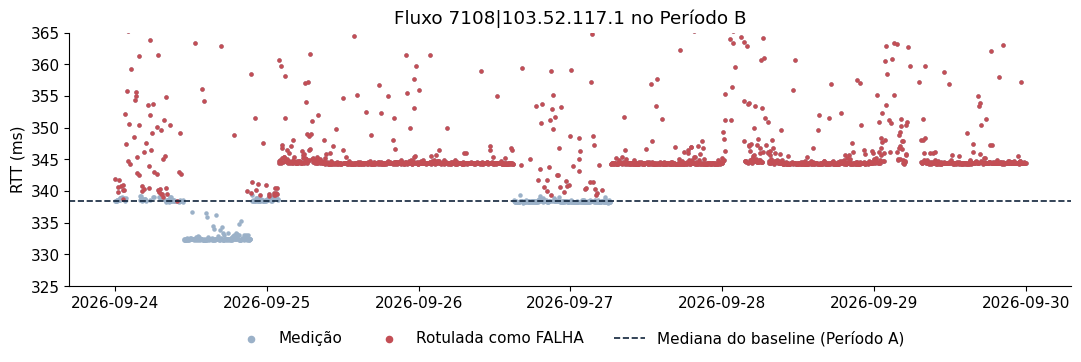

In [12]:
JANELA = 90
ordenado = det.sort_values(["fluxo_id", "timestamp_utc"]).copy()
g = ordenado.groupby("fluxo_id")
rolar = lambda coluna, funcao: g[coluna].transform(lambda s: getattr(s.rolling(JANELA, min_periods=JANELA), funcao)())
z_janela = rolar("z_robusto", "median")
rtt_janela = rolar("rtt_ms", "median")
q1_j = g["rtt_ms"].transform(lambda s: s.rolling(JANELA, min_periods=JANELA).quantile(0.25))
q3_j = g["rtt_ms"].transform(lambda s: s.rolling(JANELA, min_periods=JANELA).quantile(0.75))
ordenado["janela_mudanca_rota"] = (z_janela.abs().ge(2) & ((q3_j - q1_j) / rtt_janela * 100).le(1)
                                   & rolar("perda_pct", "mean").le(2) & rolar("jitter_relativo", "median").le(1.5))

resumo_rota = ordenado.groupby("fluxo_id").agg(medicoes=("classe", "size"), marcadas=("janela_mudanca_rota", "sum"),
                                               pct_FALHA=("classe", lambda s: (s == "FALHA").mean() * 100),
                                               pct_RISCO=("classe", lambda s: (s == "RISCO").mean() * 100))
resumo_rota["pct_marcadas"] = resumo_rota["marcadas"] / resumo_rota["medicoes"] * 100
resumo_rota["mediana_A"] = ordenado.groupby("fluxo_id")["mediana"].first()
resumo_rota["mediana_B"] = ordenado.groupby("fluxo_id")["rtt_ms"].median()
resumo_rota.round(2).to_csv(SAIDA / "mudanca_rota_por_fluxo.csv")
display(resumo_rota.sort_values("pct_marcadas", ascending=False).round(2))
cruz = pd.crosstab(ordenado["janela_mudanca_rota"], ordenado["classe"])[CLASSES]
cruz.to_csv(SAIDA / "mudanca_rota_por_classe.csv")
display(cruz)
print(f"Linhas marcadas: {ordenado.janela_mudanca_rota.sum()} de {len(ordenado)} ({ordenado.janela_mudanca_rota.mean():.1%})")
print(f"Das FALHA, {cruz.loc[True, 'FALHA'] / cruz['FALHA'].sum():.1%} estão em janela marcada; das RISCO, {cruz.loc[True, 'RISCO'] / cruz['RISCO'].sum():.1%}.")

marcadas = ordenado.loc[ordenado.janela_mudanca_rota, ["fluxo_id", "timestamp_utc"]].assign(marcada=True)
marcar = lambda t: t.merge(marcadas, on=["fluxo_id", "timestamp_utc"], how="left")["marcada"].notna().values
tr_limpo = treino[~marcar(treino)]
linhas = []
te_marc = marcar(teste_f)
for nome, (familia, params) in {"Árvore de Decisão": ("arvore", PARAMS_OFICIAL),
                                "Random Forest": ("floresta", melhores_det["floresta"]),
                                "XGBoost": ("xgboost", melhores_det["xgboost"])}.items():
    m = treinar(familia, params, tr_limpo[FEATURES], y_cod(tr_limpo["classe"]))
    p = nomes(prever(m, teste_f[FEATURES]))
    linhas.append({"Modelo": nome, "Teste": "completo", **metricas(teste_f["classe"].values, p)})
    linhas.append({"Modelo": nome, "Teste": "sem linhas marcadas", **metricas(teste_f["classe"].values[~te_marc], p[~te_marc])})
tab_rota = pd.DataFrame(linhas).set_index(["Modelo", "Teste"])
tab_rota.round(4).to_csv(SAIDA / "sensibilidade_mudanca_rota.csv")
print("Treino sem marcadas:", len(tr_limpo), "de", len(treino))
display(tab_rota[["F1 macro", "Recall FALHA", "Recall RISCO", "Erros", "N"]].round(4))

fig, eixo = plt.subplots(figsize=(11, 3.8))
x = ordenado[ordenado.fluxo_id.eq("7108|103.52.117.1")]
eixo.scatter(x["timestamp_utc"], x["rtt_ms"], s=5, color="#9bb1c8", label="Medição")
eixo.scatter(x.loc[x.classe.eq("FALHA"), "timestamp_utc"], x.loc[x.classe.eq("FALHA"), "rtt_ms"], s=5, color=CORES["FALHA"], label="Rotulada como FALHA")
eixo.axhline(x["mediana"].iloc[0], color="#10243b", ls="--", lw=1.2, label="Mediana do baseline (Período A)")
eixo.set_ylim(325, 365); eixo.set_ylabel("RTT (ms)"); eixo.set_title("Fluxo 7108|103.52.117.1 no Período B")
eixo.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12), markerscale=2)
fig.tight_layout(); fig.savefig(FIGURAS / "mudanca_rota_7108.png", dpi=150, bbox_inches="tight"); plt.show()


## 9. Figuras de apoio para o artigo

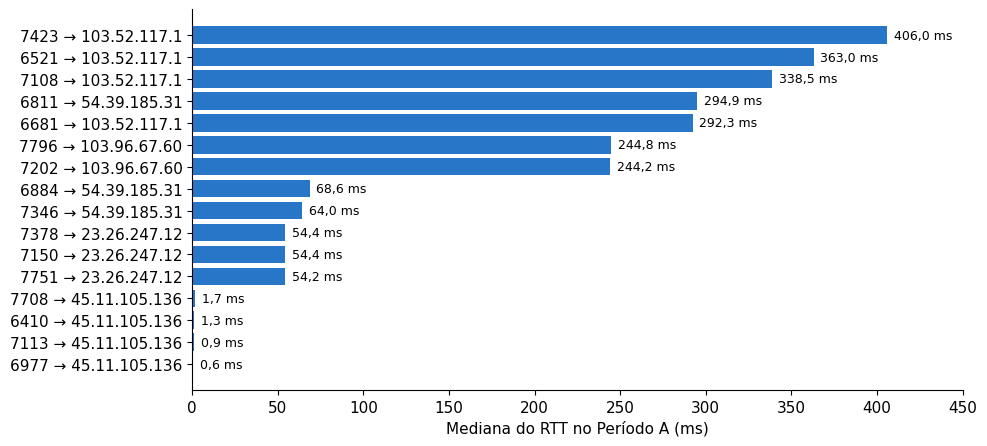

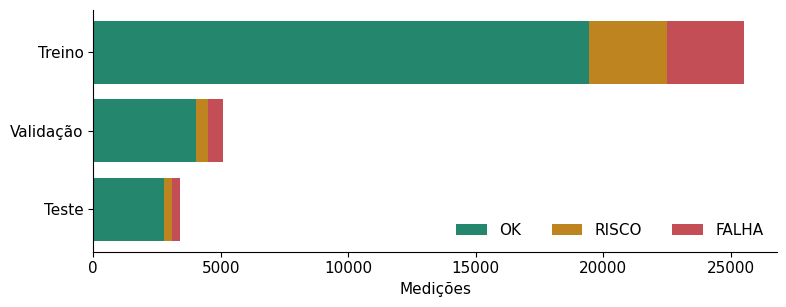

classe,OK,RISCO,FALHA
bloco_temporal,,,
treino,19451,3047,3047
validacao,4035,484,583
teste,2788,317,312


classe,OK,RISCO,FALHA
fluxo_id,,,
6410|45.11.105.136,73.4,11.3,15.4
6521|103.52.117.1,81.5,16.2,2.3
6681|103.52.117.1,5.7,91.4,2.9
6811|54.39.185.31,87.5,1.1,11.4
6884|54.39.185.31,92.5,2.3,5.2
6977|45.11.105.136,95.4,2.6,2.1
7108|103.52.117.1,18.4,1.9,79.7
7113|45.11.105.136,94.8,2.0,3.2
7150|23.26.247.12,99.5,0.3,0.2


In [13]:
# Distância não é defeito: um caminho curto e um longo, cada um com seu normal.
base = pd.read_csv(PROCESSED / "baseline_por_fluxo.csv")
ok = base[base.status_baseline.eq("baseline_ok")].sort_values("mediana")
fig, eixo = plt.subplots(figsize=(10, 4.6))
rotulos_f = [f.replace("|", " → ") for f in ok["fluxo_id"]]
eixo.barh(rotulos_f, ok["mediana"], color="#2876c7")
for i, v in enumerate(ok["mediana"]):
    eixo.text(v + 4, i, f"{v:.1f} ms".replace(".", ","), va="center", fontsize=9)
eixo.set_xlabel("Mediana do RTT no Período A (ms)"); eixo.set_xlim(0, 450)
fig.tight_layout(); fig.savefig(FIGURAS / "baseline_por_fluxo.png", dpi=150); plt.show()

# Distribuição das classes por bloco.
dist = pd.crosstab(det["bloco_temporal"], det["classe"]).reindex(index=["treino", "validacao", "teste"], columns=CLASSES)
dist.to_csv(SAIDA / "distribuicao_classes.csv")
fig, eixo = plt.subplots(figsize=(8, 3.2))
esquerda = np.zeros(3)
nomes_blocos = ["Treino", "Validação", "Teste"]
for cl in CLASSES:
    eixo.barh(nomes_blocos, dist[cl], left=esquerda, color=CORES[cl], label=cl)
    esquerda += dist[cl].values
eixo.invert_yaxis(); eixo.set_xlabel("Medições"); eixo.legend(frameon=False, ncol=3, loc="lower right")
fig.tight_layout(); fig.savefig(FIGURAS / "distribuicao_classes.png", dpi=150); plt.show()
display(dist)
display((pd.crosstab(det["fluxo_id"], det["classe"], normalize="index") * 100)[CLASSES].round(1))


In [ ]:
# Não exportar uma segunda árvore escolhida na Tarefa 6.
# A única Árvore de Decisão oficial é a gerada pela Tarefa 5.
print("Árvore de Decisão carregada de:", CAMINHO_OFICIAL)

In [14]:
# Registro final: modelo escolhido, parâmetros e ambiente.
resumo = {
    "modelo_escolhido_na_validacao": ESCOLHIDO,
    "arvore_oficial": "Tarefa 5",
    "arquivo_arvore_oficial": str(CAMINHO_OFICIAL),
    "parametros": {n: i["params"] for n, i in finais.items()},
    "limiares": {n: i["limiar"] for n, i in finais.items()},
    "parametros_preditor": {n: i["params"] for n, i in finais_pred.items()},
    "xgboost_arvores_early_stopping": int(finais["XGBoost"]["modelo"].named_steps["modelo"].best_iteration + 1),
    "oob_floresta": float(oob.oob_score_),
    "ambiente": {"python": platform.python_version(), "scikit_learn": sklearn.__version__, "xgboost": xgboost.__version__,
                 "pandas": pd.__version__, "numpy": np.__version__, "joblib": joblib.__version__},
}
with open(SAIDA / "resumo_tarefa6.json", "w", encoding="utf-8") as f:
    json.dump(resumo, f, ensure_ascii=False, indent=2)
print(json.dumps(resumo, ensure_ascii=False, indent=2))


{
  "modelo_escolhido_na_validacao": "Árvore de Decisão",
  "arvore_oficial": "Tarefa 5",
  "arquivo_arvore_oficial": "/content/drive/MyDrive/ripe_atlas/entrega_final/modelo.joblib",
  "parametros": {
    "Árvore de Decisão": {
      "criterion": "entropy",
      "max_depth": 5,
      "min_samples_leaf": 10,
      "balanceado": false
    },
    "Random Forest": {
      "balanceado": false,
      "max_depth": 12,
      "max_features": "sqrt",
      "min_samples_leaf": 1,
      "n_estimators": 100
    },
    "XGBoost": {
      "balanceado": true,
      "learning_rate": 0.05,
      "max_depth": 3,
      "n_estimators": 200,
      "reg_lambda": 1
    }
  },
  "limiares": {
    "Árvore de Decisão": null,
    "Random Forest": null,
    "XGBoost": 0.1
  },
  "parametros_preditor": {
    "Árvore de Decisão": {
      "criterion": "entropy",
      "max_depth": 5,
      "min_samples_leaf": 10,
      "balanceado": false
    },
    "Random Forest": {
      "balanceado": false,
      "max_depth": nu

**Nota de revisão:** a comparação atual usa somente a Árvore de Decisão oficial da Tarefa 5, Random Forest e XGBoost. Os resultados e interpretações anteriores foram retirados porque dependiam de outra divisão e do horizonte de 12 minutos. Preencher esta análise somente após executar novamente os notebooks e conferir os CSVs gerados.